<a href="https://colab.research.google.com/github/kotok9/app-stat-lab01/blob/main/lab01_style.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 — единый стиль графиков
Настройки стиля для всей лабораторной работы задаются одним кодом в ячейке ниже.
Цвета и значения: синий — данные, оранжевый — теоретическая кривая, фиолетовый — акценты, серо-голубой — второстепенные линии, бирюзовый и малиновый — запасные. Данная палитра продумана специально для темы космоса. Шрифт выбран "DejaVu Sans", так как он встроен в matplotlib, поэтому одинаков в Colab, на GitHub и локально, а также поддерживает кириллицу. Фон белый, сетка светло-серая, верхняя и правая рамки убраны - для удобного просмотра и схожей демонстрации на обеих платформах.

In [1]:
#@title Стиль графиков — запустить один раз в начале { display-mode: "form" }
import matplotlib as mpl
import matplotlib.pyplot as plt

# Палитра «космос»: имена переменных не менять, на них опираются остальные ноутбуки
C_DATA   = "#1F4E8C"   # данные — глубокий синий ночного неба
C_THEORY = "#E85D04"   # теоретическая кривая — раскалённый оранжевый болида
C_ACCENT = "#9B5DE5"   # выделение — фиолетовый туманности
C_MUTED  = "#8A94A6"   # второстепенные элементы — серо-голубая дымка
C_PALETTE = [C_DATA, C_THEORY, C_ACCENT, C_MUTED, "#2A9D8F", "#C9184A"]

# Блок Б: размер и разрешение всех картинок
mpl.rcParams.update({
    "figure.figsize": (9, 5.2),    # размер картинки в дюймах
    "figure.dpi": 110,             # качество на экране
    "savefig.dpi": 150,            # качество при сохранении в файл
    "figure.facecolor": "white",   # белый фон вокруг осей
    "axes.facecolor": "white",     # белый фон внутри осей
    "savefig.facecolor": "white",
})

# Блок В: шрифты
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
})

# Блок Г: рамки и сетка
mpl.rcParams.update({
    "axes.edgecolor": "#B9C0CC",
    "axes.linewidth": 1.0,
    "axes.spines.top": False,     # убрать верхнюю рамку
    "axes.spines.right": False,   # убрать правую рамку
    "axes.grid": True,
    "axes.axisbelow": True,       # сетка под данными, а не поверх
    "grid.color": "#D9DEE7",
    "grid.linewidth": 0.8,
    "grid.alpha": 0.7,
})

# Блок Д: деления на осях
mpl.rcParams.update({
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.color": "#4A5568",
    "ytick.color": "#4A5568",
})

# Блок Е: линии, легенда и порядок цветов
mpl.rcParams.update({
    "lines.linewidth": 2.0,
    "lines.markersize": 6,
    "legend.frameon": False,      # легенда без рамки
    "legend.fontsize": 10,
    "axes.prop_cycle": mpl.cycler(color=C_PALETTE),  # цвета серий по умолчанию
})

print("Стиль применён. Палитра:", C_PALETTE)

Стиль применён. Палитра: ['#1F4E8C', '#E85D04', '#9B5DE5', '#8A94A6', '#2A9D8F', '#C9184A']


## 1. Гистограмма с теоретической кривой
Проверяет базовую картинку лабораторной работы. А именно: форму выборки и то, насколько она совпадает с теорией.

---

Вершины столбцов повторяют оранжевую кривую. К центру они выше, а по краям плавно спадают. Столбцы выборки синие (`C_DATA`), а теоретическая
плотность оранжевая (`C_THEORY`).

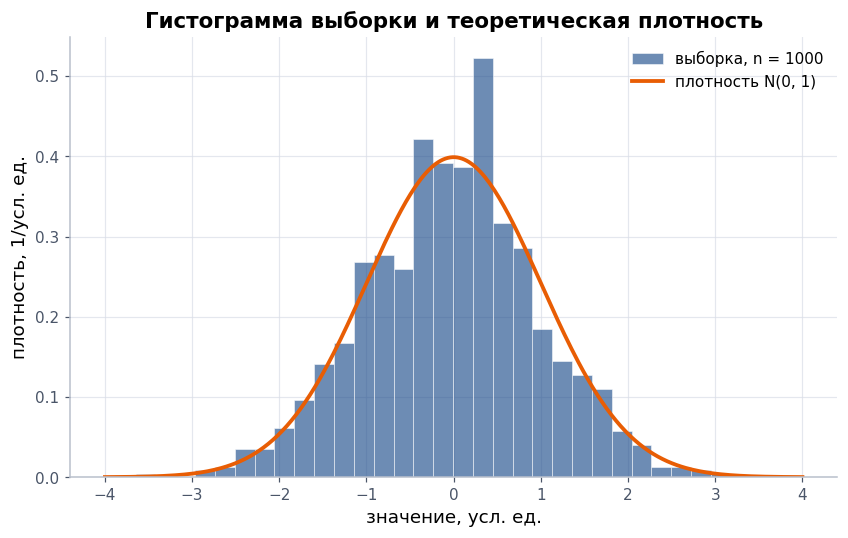

In [2]:
#@title Пример 1. Гистограмма с теоретической кривой
import numpy as np

rng = np.random.default_rng(42)
sample = rng.normal(loc=0.0, scale=1.0, size=1000)

fig, ax = plt.subplots()
ax.hist(sample, bins=30, density=True, color=C_DATA, alpha=0.65,
        edgecolor="white", linewidth=0.5, label="выборка, n = 1000")

x = np.linspace(-4, 4, 300)
pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
ax.plot(x, pdf, color=C_THEORY, linewidth=2.5, label="плотность N(0, 1)")

ax.set_title("Гистограмма выборки и теоретическая плотность")
ax.set_xlabel("значение, усл. ед.")
ax.set_ylabel("плотность, 1/усл. ед.")
ax.legend()
plt.show()

## 2. Ящик с усами
Три группы в одном. Таким образом удобно сравнивать медианы и размахи между собой.

---

Группа 2: медиана выше и ящик самый широкий, то есть разброс наибольший. У группы 3 центр ниже всех и ящик самый узкий. Ящики залиты цветами палитры, каждый своим.

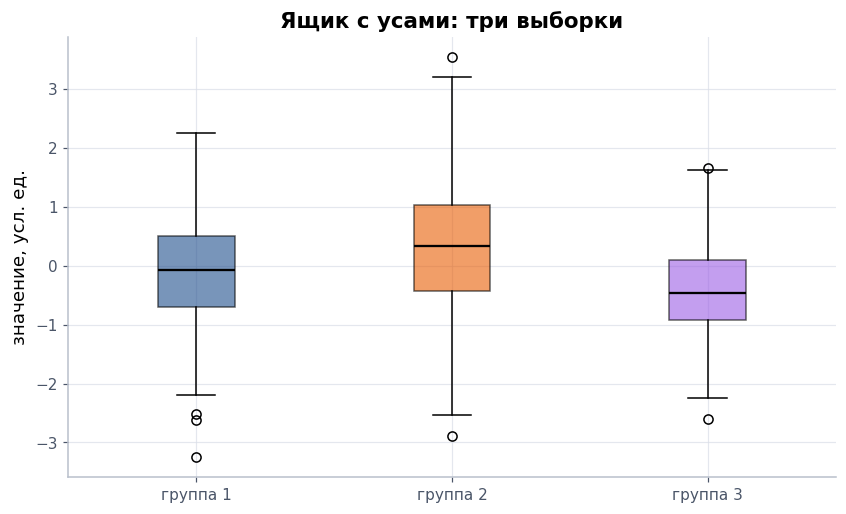

In [3]:
#@title Пример 2. Ящик с усами
rng = np.random.default_rng(7)
groups = [rng.normal(0.0, 1.0, 300), rng.normal(0.5, 1.2, 300), rng.normal(-0.4, 0.8, 300)]

fig, ax = plt.subplots()
boxes = ax.boxplot(groups, patch_artist=True,
                   medianprops={"color": "black", "linewidth": 1.5})
for patch, color in zip(boxes["boxes"], C_PALETTE):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["группа 1", "группа 2", "группа 3"])
ax.set_title("Ящик с усами: три выборки")
ax.set_ylabel("значение, усл. ед.")
plt.show()

## 3. Точечный график
Связь двух величин: точки вытянуты вдоль оранжевого тренда.


---

С ростом X растёт и Y. Точки полупрозрачные, поэтому там, где наблюдений больше,
цвет темнее, видна плотность скоплений. Точки синие (`C_DATA`), а
линия тренда оранжевая (`C_THEORY`).

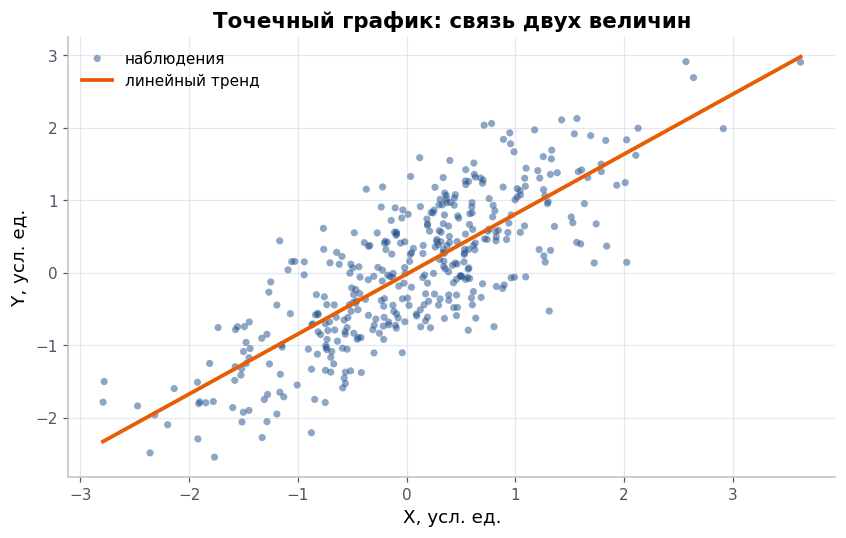

In [4]:
#@title Пример 3. Точечный график
rng = np.random.default_rng(11)
x = rng.normal(0.0, 1.0, 400)
y = 0.8 * x + rng.normal(0.0, 0.6, 400)

fig, ax = plt.subplots()
ax.scatter(x, y, s=22, color=C_DATA, alpha=0.5, edgecolors="none", label="наблюдения")

b1 = np.cov(x, y)[0, 1] / np.var(x)
b0 = y.mean() - b1 * x.mean()
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, b0 + b1 * xs, color=C_THEORY, linewidth=2.5, label="линейный тренд")

ax.set_title("Точечный график: связь двух величин")
ax.set_xlabel("X, усл. ед.")
ax.set_ylabel("Y, усл. ед.")
ax.legend()
plt.show()

## 4. Линия во времени
Модель потока болидов: линия показывает, сколько событий накопилось к каждому
дню, и растёт ступеньками, то есть после каждого падения ещё один шаг вверх.


---


Серый пунктир показывает полный объём наблюдения (все 40 событий), фиолетовый вертикальный отвечает за день, к которому упала половина из них. Этот пример является заготовкой генератора: тот же показательный поток, но там средний интервал можно менять.

In [ ]:
#@title Пример 4. Линия во времени
rng = np.random.default_rng(13)
n_events = 40
intervals = rng.exponential(scale=11.0, size=n_events)   # интервалы между падениями
moments = np.cumsum(intervals)                           # моменты падений, дней

grid = np.linspace(0.0, moments[-1], 400)
counts = np.searchsorted(moments, grid, side="right")    # сколько упало к моменту t

fig, ax = plt.subplots()
ax.plot(grid, counts, color=C_DATA, linewidth=2.5, label="накопленное число болидов")
ax.axhline(n_events, color=C_MUTED, linestyle="--", linewidth=1.5,
           label=f"всего событий: {n_events}")
mid = moments[n_events // 2]
ax.axvline(mid, color=C_ACCENT, linestyle=":", linewidth=2,
           label=f"50% событий к {mid:.0f}-му дню")

ax.set_title("Линия во времени: накопленное число событий")
ax.set_xlabel("время, дней")
ax.set_ylabel("число событий")
ax.legend()
plt.show()

## Чек-лист стиля

*   ячейка стиля запускается первой, один раз, а дальше все графики получают общий размер, шрифты, сетку и цвета;
*   **данные:** синие `(C_DATA)`; **теория:** оранжевая `(C_THEORY)`; **выделение:** фиолетовое `(C_ACCENT)`; **оставшееся, второстепенное:** серо-голубое `(C_MUTED)`;
*   верхней и правой рамки нет, легенда без рамки;
*   у каждого графика есть заголовок и подписи осей с единицами измерения;
ячейка стиля копируется без изменений в начало остальных ноутбуков лабораторной работы